# Project 3 — Major
K-Means and Hierarchical Clustering

## 1. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
K_VALUES = range(2, 11)
pd.set_option("display.max_columns", None)

## 2. Load and Prepare Data

In [2]:
# Load dataset
df = pd.read_csv("degrees-that-pay-back.csv")
identifier = 'Undergraduate_Major'
target = None

print(df.shape)
display(df.head())
print("Missing values:")
print(df.isna().sum())

# Select salary features
exclude = [identifier] + ([target] if target is not None else [])
numeric_cols = [c for c in df.columns if c not in exclude]
X = df[numeric_cols].copy()

# Convert salary columns to numeric
for col in numeric_cols:
    X[col] = pd.to_numeric(
        X[col].astype(str)
              .str.replace(r"[$,%]", "", regex=True)
              .str.replace(",", "", regex=False),
        errors="coerce"
    )

# Median imputation
X = X.fillna(X.median())

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Missing after preprocessing:", X.isna().sum().sum())

(50, 8)


,Undergraduate_Major,Starting Median Salary,Mid-Career Median Salary,Percent change from Starting to Mid-Career Salary,Mid-Career 10th Percentile Salary,Mid-Career 25th Percentile Salary,Mid-Career 75th Percentile Salary,Mid-Career 90th Percentile Salary
0,Accounting,46000,77100,67.6,42200,56100,108000,152000
1,Aerospace Engineering,57700,101000,75.0,64300,82100,127000,161000
2,Agriculture,42600,71900,68.8,36300,52100,96300,150000
3,Anthropology,36800,61500,67.1,33800,45500,89300,138000
4,Architecture,41600,76800,84.6,50600,62200,97000,136000


Missing values:
Undergraduate_Major                                  0
Starting Median Salary                               0
Mid-Career Median Salary                             0
Percent change from Starting to Mid-Career Salary    0
Mid-Career 10th Percentile Salary                    0
Mid-Career 25th Percentile Salary                    0
Mid-Career 75th Percentile Salary                    0
Mid-Career 90th Percentile Salary                    0
dtype: int64
Missing after preprocessing: 0


## 3. K-Means — Round 1: Find the Best K

In [3]:
# Test K = 2 to 10
km_results = []
km_labels = {}

for k in K_VALUES:
    model = KMeans(
        n_clusters=k, init="k-means++", n_init=20,
        max_iter=300, tol=0.0001, algorithm="lloyd",
        random_state=SEED
    )
    labels = model.fit_predict(X_scaled)
    km_labels[k] = labels

    result = {
        "K": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "SSE": model.inertia_,
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    km_results.append(result)

km_round1 = pd.DataFrame(km_results)
display(km_round1.round(4))

best_k_km = int(km_round1.loc[km_round1["Silhouette"].idxmax(), "K"])
print("Best K =", best_k_km)

C:\Users\urang\anaconda3\envs\ds69\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\urang\anaconda3\envs\ds69\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

,K,Silhouette,SSE,Cluster Size
0,2,0.4577,155.9122,"[23, 27]"
1,3,0.4205,96.0976,"[12, 17, 21]"
2,4,0.3645,76.8362,"[8, 10, 15, 17]"
3,5,0.3334,64.4411,"[4, 9, 10, 13, 14]"
4,6,0.3489,51.8201,"[3, 4, 9, 9, 12, 13]"
5,7,0.3592,42.3942,"[1, 2, 4, 9, 9, 12, 13]"
6,8,0.3438,36.4093,"[1, 1, 4, 5, 7, 9, 11, 12]"
7,9,0.3364,30.7719,"[1, 1, 4, 4, 4, 5, 8, 11, 12]"
8,10,0.3168,26.7506,"[1, 1, 4, 4, 4, 5, 5, 7, 8, 11]"


Best K = 2


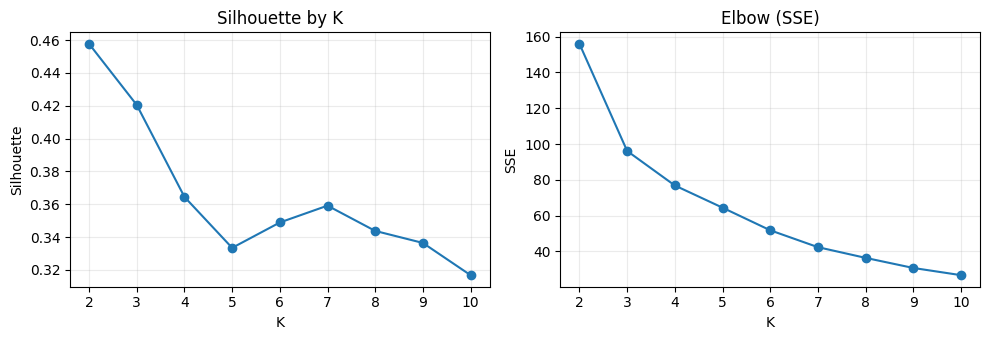

In [4]:
# Silhouette and Elbow plots
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(km_round1["K"], km_round1["Silhouette"], marker="o")
axes[0].set(xlabel="K", ylabel="Silhouette", title="Silhouette by K")
axes[1].plot(km_round1["K"], km_round1["SSE"], marker="o")
axes[1].set(xlabel="K", ylabel="SSE", title="Elbow (SSE)")
for ax in axes:
    ax.set_xticks(list(K_VALUES))
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [5]:
# Check important K candidates
profile_cols = [c for c in [
    "Starting Median Salary",
    "Mid-Career Median Salary",
    "Percent change from Starting to Mid-Career Salary",
    "Mid-Career 90th Percentile Salary"
] if c in X.columns]

for k in [2, 3]:
    check = X.copy()
    check[identifier] = df[identifier]
    check["Cluster"] = km_labels[k]

    print("\nK =", k)
    print("Cluster Size:")
    print(check["Cluster"].value_counts().sort_index())
    print("Cluster Profile:")
    display(check.groupby("Cluster")[profile_cols].mean().round(1))


K = 2
Cluster Size:
Cluster
0    27
1    23
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Percent change from Starting to Mid-Career Salary,Mid-Career 90th Percentile Salary
Cluster,,,,
0,38514.8,62085.2,61.8,124011.1
1,51113.0,89695.7,78.0,164782.6



K = 3
Cluster Size:
Cluster
0    17
1    21
2    12
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Percent change from Starting to Mid-Career Salary,Mid-Career 90th Percentile Salary
Cluster,,,,
0,42058.8,77435.3,84.4,156117.6
1,38261.9,59814.3,57.2,118014.3
2,58083.3,97233.3,69.0,167166.7


## 4. K-Means — Round 2: init × n_init

In [6]:
# Test K-Means configurations using the selected K
km_round2_results = []

for init in ["k-means++", "random"]:
    for n_init in [1, 10, 20, 50]:
        model = KMeans(
            n_clusters=best_k_km, init=init, n_init=n_init,
            max_iter=300, tol=0.0001, algorithm="lloyd",
            random_state=SEED
        )
        labels = model.fit_predict(X_scaled)

        result = {
            "init": init,
            "n_init": n_init,
            "Silhouette": silhouette_score(X_scaled, labels),
            "SSE": model.inertia_,
            "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
        }
        km_round2_results.append(result)

km_round2 = pd.DataFrame(km_round2_results)
display(km_round2.round(4))

# Final K-Means configuration
km_final = KMeans(
    n_clusters=best_k_km, init="k-means++", n_init=10,
    max_iter=300, tol=0.0001, algorithm="lloyd",
    random_state=SEED
)
km_final_labels = km_final.fit_predict(X_scaled)
km_final_silhouette = silhouette_score(X_scaled, km_final_labels)
print("Final K-Means Silhouette =", round(km_final_silhouette, 4))
print("Cluster Size:", sorted(pd.Series(km_final_labels).value_counts().tolist()))

,init,n_init,Silhouette,SSE,Cluster Size
0,k-means++,1,0.4577,155.9122,"[23, 27]"
1,k-means++,10,0.4577,155.9122,"[23, 27]"
2,k-means++,20,0.4577,155.9122,"[23, 27]"
3,k-means++,50,0.4577,155.9122,"[23, 27]"
4,random,1,0.4577,155.9122,"[23, 27]"
5,random,10,0.4577,155.9122,"[23, 27]"
6,random,20,0.4577,155.9122,"[23, 27]"
7,random,50,0.4577,155.9122,"[23, 27]"


Final K-Means Silhouette = 0.4577
Cluster Size: [23, 27]


## 5. Hierarchical — Round 1: Find the Best K

In [7]:
# Ward + Euclidean, K = 2 to 10
h_results = []
h_labels = {}

for k in K_VALUES:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean")
    labels = model.fit_predict(X_scaled)
    h_labels[k] = labels

    result = {
        "K": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    h_results.append(result)

h_round1 = pd.DataFrame(h_results)
display(h_round1.round(4))

best_k_h = int(h_round1.loc[h_round1["Silhouette"].idxmax(), "K"])
print("Best K =", best_k_h)

,K,Silhouette,Cluster Size
0,2,0.4802,"[15, 35]"
1,3,0.3867,"[15, 16, 19]"
2,4,0.4156,"[2, 13, 16, 19]"
3,5,0.4026,"[2, 4, 9, 16, 19]"
4,6,0.3668,"[2, 4, 4, 9, 12, 19]"
5,7,0.3051,"[2, 4, 4, 9, 9, 10, 12]"
6,8,0.3082,"[1, 1, 4, 4, 9, 9, 10, 12]"
7,9,0.2938,"[1, 1, 4, 4, 4, 5, 9, 10, 12]"
8,10,0.3024,"[1, 1, 4, 4, 4, 4, 5, 8, 9, 10]"


Best K = 2


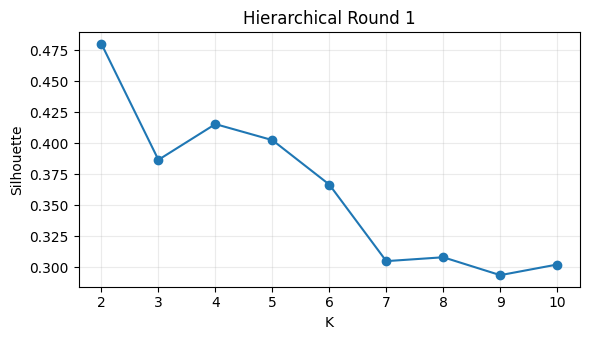

In [8]:
# Silhouette plot
plt.figure(figsize=(6, 3.5))
plt.plot(h_round1["K"], h_round1["Silhouette"], marker="o")
plt.xticks(list(K_VALUES))
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.title("Hierarchical Round 1")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Hierarchical — Round 2: linkage × metric

In [9]:
# Test linkage and metric configurations
configs = [("ward", "euclidean")]
for link in ["complete", "average", "single"]:
    for metric in ["euclidean", "manhattan", "cosine"]:
        configs.append((link, metric))

h_round2_results = []
h_round2_labels = {}

for link, metric in configs:
    model = AgglomerativeClustering(
        n_clusters=best_k_h, linkage=link, metric=metric
    )
    labels = model.fit_predict(X_scaled)
    h_round2_labels[(link, metric)] = labels

    result = {
        "linkage": link,
        "metric": metric,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    h_round2_results.append(result)

h_round2 = pd.DataFrame(h_round2_results)
display(h_round2.round(4))

,linkage,metric,Silhouette,Cluster Size
0,ward,euclidean,0.4802,"[15, 35]"
1,complete,euclidean,0.4394,"[19, 31]"
2,complete,manhattan,0.4394,"[19, 31]"
3,complete,cosine,0.4414,"[22, 28]"
4,average,euclidean,0.3351,"[2, 48]"
5,average,manhattan,0.3704,"[1, 49]"
6,average,cosine,0.4414,"[22, 28]"
7,single,euclidean,0.3704,"[1, 49]"
8,single,manhattan,0.3704,"[1, 49]"
9,single,cosine,0.4309,"[25, 25]"


In [10]:
# Final Hierarchical configuration
final_linkage = 'ward'
final_metric = 'euclidean'
h_final_labels = h_round2_labels[(final_linkage, final_metric)]
h_final_silhouette = silhouette_score(X_scaled, h_final_labels)

print("Final Hierarchical:", final_linkage, "+", final_metric)
print("Silhouette =", round(h_final_silhouette, 4))
print("Cluster Size:", sorted(pd.Series(h_final_labels).value_counts().tolist()))

Final Hierarchical: ward + euclidean
Silhouette = 0.4802
Cluster Size: [15, 35]


## 7. Dendrogram Check

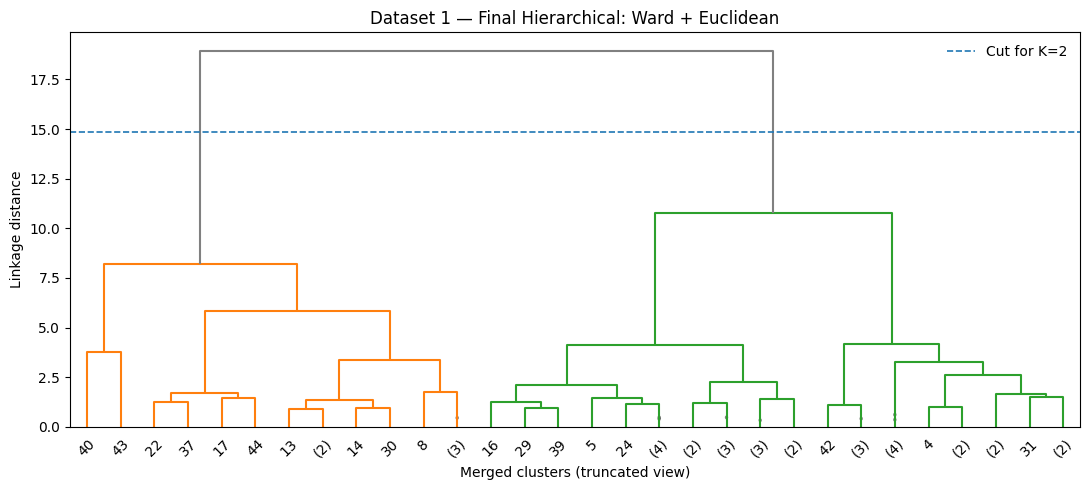

In [11]:
# Final Hierarchical: Ward + Euclidean
Z = linkage(X_scaled, method='ward', metric='euclidean')
cut_height = (Z[-best_k_h, 2] + Z[-(best_k_h - 1), 2]) / 2

plt.figure(figsize=(11, 5))
dendrogram(
    Z, truncate_mode="lastp", p=min(30, len(X_scaled)),
    show_contracted=True, color_threshold=cut_height,
    above_threshold_color="grey"
)
plt.axhline(cut_height, linestyle="--", linewidth=1.2, label=f"Cut for K={best_k_h}")
plt.title("Dataset 1 — Final Hierarchical: Ward + Euclidean")
plt.xlabel("Merged clusters (truncated view)")
plt.ylabel("Linkage distance")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Final Comparison and Cluster Profile

In [12]:
# Compare final K-Means and Hierarchical models
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Silhouette": [km_final_silhouette, h_final_silhouette],
    "Cluster Size": [
        sorted(pd.Series(km_final_labels).value_counts().tolist()),
        sorted(pd.Series(h_final_labels).value_counts().tolist())
    ]
})
display(comparison.round(4))

# Final Hierarchical cluster size and profile
final_df = X.copy()
final_df[identifier] = df[identifier]
final_df["Cluster"] = h_final_labels

print("Cluster Size:")
print(final_df["Cluster"].value_counts().sort_index())

print("Cluster Profile:")
display(final_df.groupby("Cluster")[profile_cols].mean().round(1))
print("Members in each cluster:")
for cluster in sorted(final_df["Cluster"].unique()):
    members = final_df.loc[final_df["Cluster"] == cluster, identifier].tolist()
    print(f"Cluster {cluster} (n={len(members)}):")
    print(", ".join(map(str, members)))

,Algorithm,Silhouette,Cluster Size
0,K-Means,0.4577,"[23, 27]"
1,Hierarchical,0.4802,"[15, 35]"


Cluster Size:
Cluster
0    35
1    15
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Percent change from Starting to Mid-Career Salary,Mid-Career 90th Percentile Salary
Cluster,,,,
0,39171.4,66422.9,69.3,133028.6
1,56300.0,94300.0,69.3,165486.7


Members in each cluster:
Cluster 0 (n=35):
Accounting, Agriculture, Anthropology, Architecture, Art History, Biology, Business Management, Chemistry, Communications, Criminal Justice, Drama, Education, English, Film, Forestry, Geography, Geology, Graphic Design, Health Care Administration, History, Hospitality & Tourism, Information Technology (IT), Interior Design, International Relations, Journalism, Management Information Systems (MIS), Marketing, Music, Nutrition, Philosophy, Political Science, Psychology, Religion, Sociology, Spanish
Cluster 1 (n=15):
Aerospace Engineering, Chemical Engineering, Civil Engineering, Computer Engineering, Computer Science, Construction, Economics, Electrical Engineering, Finance, Industrial Engineering, Math, Mechanical Engineering, Nursing, Physician Assistant, Physics


## 9. Final Cluster Profile Chart

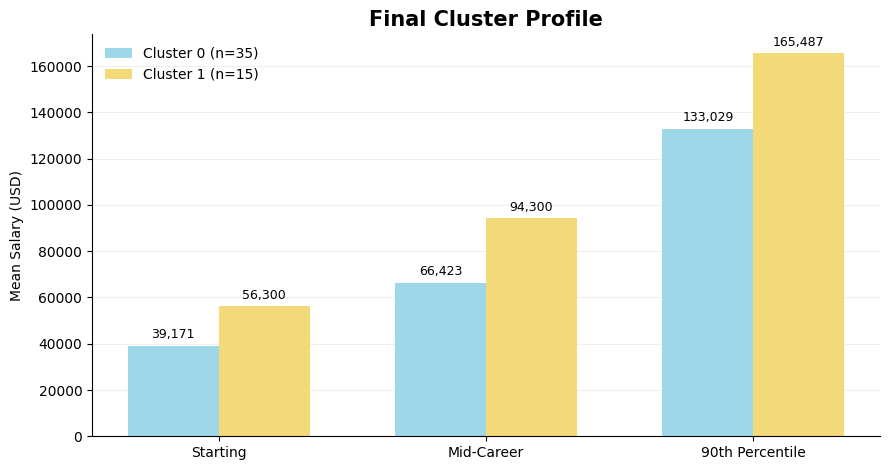

In [13]:
# Final Cluster Profile bar chart
chart_features = [c for c in [
    "Starting Median Salary",
    "Mid-Career Median Salary",
    "Mid-Career 90th Percentile Salary"
] if c in final_df.columns]

profile_chart = final_df.groupby("Cluster")[chart_features].mean()
cluster_order = profile_chart["Mid-Career Median Salary"].sort_values().index.tolist()
profile_chart = profile_chart.loc[cluster_order]

SLIDE_BLUE = "#9ED7E8"
SLIDE_YELLOW = "#F4D978"
colors = [SLIDE_BLUE, SLIDE_YELLOW]

short_names = {
    "Starting Median Salary": "Starting",
    "Mid-Career Median Salary": "Mid-Career",
    "Mid-Career 90th Percentile Salary": "90th Percentile"
}

x = range(len(chart_features))
width = 0.34
fig, ax = plt.subplots(figsize=(9, 4.8))

for i, cluster in enumerate(cluster_order):
    offset = (i - (len(cluster_order) - 1) / 2) * width
    values = profile_chart.loc[cluster].values
    n = int((final_df["Cluster"] == cluster).sum())
    bars = ax.bar(
        [v + offset for v in x], values, width,
        label=f"Cluster {cluster} (n={n})",
        color=colors[i % len(colors)]
    )
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=3, fontsize=9)

ax.set_title("Final Cluster Profile", fontsize=15, weight="bold")
ax.set_ylabel("Mean Salary (USD)")
ax.set_xticks(list(x))
ax.set_xticklabels([short_names[c] for c in chart_features])
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()